# Metagenomics Abundance Barplots — 2024

Plots the CSVs exported by the R master script (`ab/csvs_2024/`).

Logic is identical to `metagenomics_plots.py`:

- most abundant taxon at the **bottom** of each bar, `Others` at the **top**
- legend order matches: most abundant at top, `Others` at bottom
- every bar is scaled 0–100%
- `PALETTE_B` (colour-blind-safe Okabe–Ito / Tol) is used for 2024; `Others` is always `#CCCCCC`

**Run order:** execute cells top to bottom. Cells 1–6 define config and functions; cell 7 writes all PNGs; cell 8 onward is for interactive single-plot work.

Requirements: `pip install pandas matplotlib numpy`

## 1 — Imports and global matplotlib settings

In [2]:
import os
import warnings
from itertools import cycle

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore")

# Render figures inline in the notebook
%matplotlib inline

# ── publication-quality defaults ──────────────────────────────────────────────
matplotlib.rcParams.update({
    "font.family"      : "sans-serif",
    "font.sans-serif"  : ["Arial", "DejaVu Sans"],
    "font.size"        : 10,
    "axes.titlesize"   : 12,
    "axes.titleweight" : "bold",
    "axes.labelsize"   : 10,
    "axes.labelweight" : "bold",
    "axes.linewidth"   : 0.8,
    "axes.spines.top"  : False,
    "axes.spines.right": False,
    "xtick.labelsize"  : 7,
    "ytick.labelsize"  : 9,
    "xtick.major.size" : 3,
    "ytick.major.size" : 3,
    "legend.fontsize"  : 8,
    "legend.frameon"   : False,
    "figure.dpi"       : 110,   # on-screen preview; savefig stays at 300
    "savefig.dpi"      : 300,
    "savefig.bbox"     : "tight",
    "savefig.facecolor": "white",
})

print("Imports OK  |  pandas", pd.__version__, "|  matplotlib", matplotlib.__version__)

Imports OK  |  pandas 2.1.4 |  matplotlib 3.7.2


## 2 — Config

`CSV_DIR_24` must point at the folder the R script wrote (`OUTPUT_DIR/csvs_2024`).
Paths are relative to the notebook's working directory — use an absolute path if the notebook lives elsewhere.

In [3]:
# ── EDIT THESE ────────────────────────────────────────────────────────────────
CSV_DIR_24   = "csvs_2024"    # folder written by the R export script
PLOT_OUT_DIR = "plots_python_1"    # where PNGs will be saved
YEAR         = "2024"

# Non-bacterial domains (archaea / eukaryota / viruses):
#   False = sample-level plots only (original script behaviour)
#   True  = also plot by_stp / by_month / by_season if those CSVs exist
PLOT_GROUP_VIEWS_FOR_NONBAC = False
# ──────────────────────────────────────────────────────────────────────────────

os.makedirs(PLOT_OUT_DIR, exist_ok=True)

MONTH_ORDER = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]

print("CSV dir :", os.path.abspath(CSV_DIR_24), "| exists:", os.path.isdir(CSV_DIR_24))
print("Plot dir:", os.path.abspath(PLOT_OUT_DIR))

if os.path.isdir(CSV_DIR_24):
    found = sorted(f for f in os.listdir(CSV_DIR_24) if f.endswith(".csv"))
    print(f"\n{len(found)} CSV file(s) found:")
    for f in found:
        print("  ", f)
else:
    print("\n!! CSV directory not found — fix CSV_DIR_24 before continuing.")

CSV dir : /data/Students/Raunak/RF-AMR-24-STP/taxa_data/csvs_2024 | exists: True
Plot dir: /data/Students/Raunak/RF-AMR-24-STP/taxa_data/plots_python_1

28 CSV file(s) found:
   arc_phyla_by_month.csv
   arc_phyla_by_season.csv
   arc_phyla_by_stp.csv
   arc_phyla_sample.csv
   bac_top10_phyla_by_month.csv
   bac_top10_phyla_by_season.csv
   bac_top10_phyla_by_stp.csv
   bac_top10_phyla_sample.csv
   bac_top15_families_by_month.csv
   bac_top15_families_by_season.csv
   bac_top15_families_by_stp.csv
   bac_top15_families_sample.csv
   bac_top15_orders_by_month.csv
   bac_top15_orders_by_season.csv
   bac_top15_orders_by_stp.csv
   bac_top15_orders_sample.csv
   bac_top20_genera_by_month.csv
   bac_top20_genera_by_season.csv
   bac_top20_genera_by_stp.csv
   bac_top20_genera_sample.csv
   euk_phyla_by_month.csv
   euk_phyla_by_season.csv
   euk_phyla_by_stp.csv
   euk_phyla_sample.csv
   vir_top15_families_by_month.csv
   vir_top15_families_by_season.csv
   vir_top15_families_by_stp.csv

## 3 — Palettes

`PALETTE_A` is kept for reference/comparison; 2024 uses `PALETTE_B`.
Colours are handed out in stack order, so index 0 (most abundant) always gets the first colour.

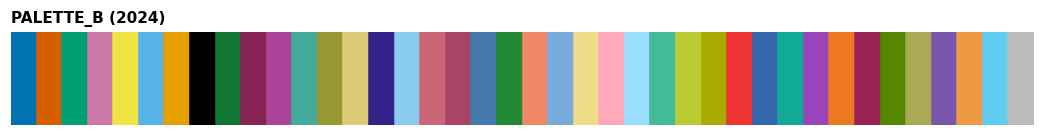

In [4]:
PALETTE_A = [
    "#E41A1C","#377EB8","#4DAF4A","#FF7F00","#984EA3",
    "#A65628","#F781BF","#1B9E77","#D95F02","#7570B3",
    "#E7298A","#66A61E","#E6AB02","#A6761D","#666666",
    "#8DD3C7","#FFFFB3","#BEBADA","#FB8072","#80B1D3",
    "#FDB462","#B3DE69","#FCCDE5","#BC80BD","#CCEBC5",
    "#1F78B4","#B2DF8A","#33A02C","#FB9A99","#E31A1C",
    "#FDBF6F","#CAB2D6","#6A3D9A","#FFFF99","#B15928",
    "#F0E442","#0072B2","#D55E00","#CC79A7","#56B4E9",
]

PALETTE_B = [
    "#0072B2","#D55E00","#009E73","#CC79A7","#F0E442",
    "#56B4E9","#E69F00","#000000","#117733","#882255",
    "#AA4499","#44AA99","#999933","#DDCC77","#332288",
    "#88CCEE","#CC6677","#AA4466","#4477AA","#228833",
    "#EE8866","#77AADD","#EEDD88","#FFAABB","#99DDFF",
    "#44BB99","#BBCC33","#AAAA00","#EE3333","#3366AA",
    "#11AA99","#9944BB","#EE7722","#992255","#558800",
    "#AAAA55","#7755AA","#EE9944","#60CCEE","#BBBBBB",
]

OTHERS_COLOUR = "#CCCCCC"


def build_palette(taxa_list, year=YEAR):
    """Map taxa -> hex colour from the year palette.

    'Others' always gets OTHERS_COLOUR. Order matters: taxa_list[0] (most
    abundant) receives the first palette colour. The palette cycles if there
    are more taxa than colours.
    """
    base = PALETTE_B if year == "2024" else PALETTE_A
    col_cycle = cycle(base)
    pal = {}
    for t in taxa_list:
        pal[t] = OTHERS_COLOUR if t == "Others" else next(col_cycle)
    return pal


# quick visual check of the 2024 palette
fig, ax = plt.subplots(figsize=(12, 1.1))
for i, c in enumerate(PALETTE_B):
    ax.add_patch(mpatches.Rectangle((i, 0), 1, 1, color=c))
ax.set_xlim(0, len(PALETTE_B)); ax.set_ylim(0, 1)
ax.set_yticks([]); ax.set_xticks([])
ax.set_title("PALETTE_B (2024)", loc="left", fontsize=10)
for s in ax.spines.values():
    s.set_visible(False)
plt.show()

## 4 — CSV loading helpers

`Row_Sum_Check` is the QC column from the R script (should read ~100 everywhere).
It gets dropped here so it is never mistaken for a taxon.

In [5]:
META_COLS = ["Sample_Date_ID", "stp", "Month_Name", "season",
             "N_Samples", "Row_Sum_Check"]


def load_csv(path):
    """Read an abundance CSV and drop the QC column."""
    df = pd.read_csv(path)
    return df.drop(columns=[c for c in ["Row_Sum_Check"] if c in df.columns])


def get_taxon_cols(df):
    """Columns holding abundance values (everything that isn't metadata)."""
    drop = [c for c in META_COLS if c in df.columns]
    return [c for c in df.columns if c not in drop]


def get_stack_order(df, taxon_cols):
    """Taxa sorted by mean abundance descending, with 'Others' appended last.

    This is the bottom-to-top plotting order: most abundant sits at the bottom
    of each bar, 'Others' on top. It is also the legend order (top to bottom).
    """
    non_others = [c for c in taxon_cols if c != "Others"]
    means = df[non_others].mean().sort_values(ascending=False)
    order = list(means.index)
    if "Others" in taxon_cols:
        order.append("Others")
    return order


def qc_report(path):
    """Print row-sum sanity check for one CSV before plotting."""
    raw = pd.read_csv(path)
    if "Row_Sum_Check" in raw.columns:
        rs = raw["Row_Sum_Check"]
        print(f"{os.path.basename(path)}: Row_Sum_Check min={rs.min():.4f} "
              f"max={rs.max():.4f}  ({len(rs)} rows)")
    else:
        tc = get_taxon_cols(raw)
        rs = raw[tc].sum(axis=1)
        print(f"{os.path.basename(path)}: row sums min={rs.min():.4f} "
              f"max={rs.max():.4f}  ({len(rs)} rows)")

## 5 — Core plot function

Bars are drawn bottom-up in `stack_order`, so the first element ends up at the
base of the bar and `Others` on top. The legend is built from the same list, so
reading the legend top-to-bottom matches reading a bar bottom-to-top.

In [6]:
def stacked_barplot(df, x_col, title, subtitle, palette, stack_order,
                    ax=None, figsize=(16, 6), x_angle=90, bar_width=0.80,
                    x_order=None):
    """Stacked bar chart of relative abundance.

    stack_order : [MostAbundant, ..., LeastAbundant, "Others"]
    x_order     : optional explicit ordering of x-axis categories
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    # x-axis ordering
    if x_order:
        present = [x for x in x_order if x in df[x_col].values]
        other_x = [x for x in df[x_col].values if x not in present]
        x_vals = present + other_x
    else:
        x_vals = list(df[x_col].values)

    df = df.set_index(x_col).reindex(x_vals)

    # draw bottom -> top
    bottoms = np.zeros(len(x_vals))
    for taxon in stack_order:
        if taxon not in df.columns:
            continue
        vals = df[taxon].fillna(0).values
        ax.bar(
            x=range(len(x_vals)),
            height=vals,
            bottom=bottoms,
            color=palette.get(taxon, OTHERS_COLOUR),
            width=bar_width,
            linewidth=0,
            label=taxon,
        )
        bottoms += vals

    # axes
    ax.set_xlim(-0.5, len(x_vals) - 0.5)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.set_xticks(range(len(x_vals)))
    ax.set_xticklabels(
        x_vals,
        rotation=x_angle,
        ha="right" if x_angle > 0 else "center",
        va="top" if x_angle > 0 else "center",
        fontsize=6.5 if len(x_vals) > 40 else 8,
        style="italic",
    )
    ax.set_ylabel("Relative Abundance (%)", fontweight="bold", fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", length=2, width=0.4, color="grey")
    ax.tick_params(axis="y", length=3, width=0.6)
    ax.yaxis.grid(True, color="grey", alpha=0.25, linewidth=0.4, zorder=0)
    ax.set_axisbelow(True)

    # title + subtitle
    # NOTE: the original script used pad=8 with the subtitle at y=1.02, which
    # made the two overlap. Title is padded clear of the subtitle line here.
    ax.set_title(title, fontweight="bold", fontsize=12, loc="left",
                 pad=24 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes,
                fontsize=9, color="grey", va="bottom")

    # legend: most abundant top, Others bottom
    handles = [
        mpatches.Patch(color=palette.get(t, OTHERS_COLOUR), label=t)
        for t in stack_order if t in df.columns
    ]
    ax.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        borderaxespad=0,
        frameon=False,
        fontsize=8,
        handlelength=1.2,
        handleheight=0.9,
    )

    fig.tight_layout()
    return fig

## 6 — Batch pipeline

File specs and view specs mirror the R export exactly. Missing CSVs are
reported and skipped rather than raising.

In [7]:
# stem -> (rank label for the title, top-N label for the subtitle)
FILES = {
    "bac_top10_phyla"    : ("Phyla",              "Top 10"),
    "bac_top15_orders"   : ("Orders",             "Top 15"),
    "bac_top15_families" : ("Families",           "Top 15"),
    "bac_top20_genera"   : ("Genera",             "Top 20"),
    "arc_phyla"          : ("Archaeal Phyla",     "\u22651% mean"),
    "euk_phyla"          : ("Eukaryotic Phyla",   "\u22651% mean"),
    "vir_top15_families" : ("Viral Families",     "Top 15"),
}

# view key -> (x column, x-label rotation, figsize)
VIEWS = {
    "sample"   : ("Sample_Date_ID", 90, (22, 7)),
    "by_stp"   : ("stp",            40, (10, 6)),
    "by_month" : ("Month_Name",     40, (11, 6)),
    "by_season": ("season",          0, (8,  6)),
}

DOMAIN_MAP = {"bac": "Bacterial", "arc": "Archaeal",
              "euk": "Eukaryotic", "vir": "Viral"}

VIEW_LBL = {"sample": "Sample Level", "by_stp": "by STP",
            "by_month": "by Month", "by_season": "by Season"}


def make_plots_for_year(csv_dir=CSV_DIR_24, year=YEAR, plot_out=PLOT_OUT_DIR,
                        show=False):
    """Generate every plot for one year from its CSV directory.

    show=True also renders each figure inline (slow for the full run).
    Returns a dict of {output_filename: figure_path} for the plots written.
    """
    year_plot_dir = os.path.join(plot_out, year)
    os.makedirs(year_plot_dir, exist_ok=True)
    written = {}

    for stem, (rank_lbl, top_lbl) in FILES.items():
        domain = stem.split("_")[0]
        domain_lbl = DOMAIN_MAP.get(domain, domain.capitalize())

        for view_key, (x_col, angle, fsize) in VIEWS.items():
            # non-bacterial domains: sample-level only unless opted in
            if (domain in ("arc", "euk", "vir")
                    and view_key != "sample"
                    and not PLOT_GROUP_VIEWS_FOR_NONBAC):
                continue

            fname = f"{stem}_{view_key}.csv"
            fpath = os.path.join(csv_dir, fname)
            if not os.path.exists(fpath):
                print(f"  [skip] {fname} not found")
                continue

            df = load_csv(fpath)
            if x_col not in df.columns:
                print(f"  [skip] column '{x_col}' missing in {fname}")
                continue

            taxon_cols = get_taxon_cols(df)
            stack_order = get_stack_order(df, taxon_cols)
            palette = build_palette(stack_order, year)

            x_order = MONTH_ORDER if x_col == "Month_Name" else None
            subtitle = f"{top_lbl} taxa + Others  |  {year}  |  {VIEW_LBL[view_key]}"
            title = f"{domain_lbl} {rank_lbl} \u2014 Relative Abundance"

            print(f"  Plotting {stem} {view_key} [{year}]...", end=" ")
            try:
                fig = stacked_barplot(
                    df=df, x_col=x_col, title=title, subtitle=subtitle,
                    palette=palette, stack_order=stack_order,
                    figsize=fsize, x_angle=angle, x_order=x_order,
                )
                out_name = f"{stem}_{view_key}.png"
                out_path = os.path.join(year_plot_dir, out_name)
                fig.savefig(out_path, dpi=300, bbox_inches="tight",
                            facecolor="white")
                written[out_name] = out_path
                if show:
                    plt.show()
                else:
                    plt.close(fig)
                print("\u2713")
            except Exception as e:
                print(f"\u2717 {e}")

    return written

## 7 — Run

Writes every PNG to `plots_python/2024/`. Set `show=True` to also display each
figure inline (much slower with the sample-level plots).

In [8]:
print(f"=== {YEAR} ===")
written = make_plots_for_year(CSV_DIR_24, YEAR, PLOT_OUT_DIR, show=False)
print(f"\n\u2713 {len(written)} plot(s) saved to: "
      f"{os.path.abspath(os.path.join(PLOT_OUT_DIR, YEAR))}")

=== 2024 ===
  Plotting bac_top10_phyla sample [2024]... ✓
  Plotting bac_top10_phyla by_stp [2024]... ✓
  Plotting bac_top10_phyla by_month [2024]... ✓
  Plotting bac_top10_phyla by_season [2024]... ✓
  Plotting bac_top15_orders sample [2024]... ✓
  Plotting bac_top15_orders by_stp [2024]... ✓
  Plotting bac_top15_orders by_month [2024]... ✓
  Plotting bac_top15_orders by_season [2024]... ✓
  Plotting bac_top15_families sample [2024]... ✓
  Plotting bac_top15_families by_stp [2024]... ✓
  Plotting bac_top15_families by_month [2024]... ✓
  Plotting bac_top15_families by_season [2024]... ✓
  Plotting bac_top20_genera sample [2024]... ✓
  Plotting bac_top20_genera by_stp [2024]... ✓
  Plotting bac_top20_genera by_month [2024]... ✓
  Plotting bac_top20_genera by_season [2024]... ✓
  Plotting arc_phyla sample [2024]... ✓
  Plotting euk_phyla sample [2024]... ✓
  Plotting vir_top15_families sample [2024]... ✓

✓ 19 plot(s) saved to: /data/Students/Raunak/RF-AMR-24-STP/taxa_data/plots_python

## 8 — Interactive single plots

Everything below is optional. Use these cells to inspect or tweak one figure at
a time without re-running the batch.

In [ ]:
# QC: confirm rows sum to 100% in each CSV
if os.path.isdir(CSV_DIR_24):
    for f in sorted(os.listdir(CSV_DIR_24)):
        if f.endswith(".csv"):
            qc_report(os.path.join(CSV_DIR_24, f))

In [ ]:
# Sample-level: bacterial phyla
path = os.path.join(CSV_DIR_24, "bac_top10_phyla_sample.csv")

df = load_csv(path)
tc = get_taxon_cols(df)
so = get_stack_order(df, tc)
pal = build_palette(so, YEAR)

print("Stack order (bottom \u2192 top):", so)

fig = stacked_barplot(
    df, "Sample_Date_ID",
    "Bacterial Phyla \u2014 Relative Abundance",
    f"Top 10 taxa + Others  |  {YEAR}  |  Sample Level",
    pal, so, figsize=(22, 7), x_angle=90,
)
plt.show()

In [ ]:
# Group-level: bacterial genera by STP
path = os.path.join(CSV_DIR_24, "bac_top20_genera_by_stp.csv")

df = load_csv(path)
tc = get_taxon_cols(df)
so = get_stack_order(df, tc)
pal = build_palette(so, YEAR)

fig = stacked_barplot(
    df, "stp",
    "Bacterial Genera by STP \u2014 Relative Abundance",
    f"Top 20 taxa + Others  |  {YEAR}",
    pal, so, figsize=(10, 6), x_angle=40,
)
plt.show()

In [ ]:
# Group-level: bacterial families by month (calendar-ordered x-axis)
path = os.path.join(CSV_DIR_24, "bac_top15_families_by_month.csv")

df = load_csv(path)
tc = get_taxon_cols(df)
so = get_stack_order(df, tc)
pal = build_palette(so, YEAR)

fig = stacked_barplot(
    df, "Month_Name",
    "Bacterial Families by Month \u2014 Relative Abundance",
    f"Top 15 taxa + Others  |  {YEAR}",
    pal, so, figsize=(11, 6), x_angle=40,
    x_order=MONTH_ORDER,
)
plt.show()

In [ ]:
# Reusable one-liner for any exported CSV
def quick_plot(stem, view, figsize=None, x_angle=None, show=True):
    """quick_plot("bac_top10_phyla", "by_season")"""
    x_col, default_angle, default_size = VIEWS[view]
    path = os.path.join(CSV_DIR_24, f"{stem}_{view}.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(path)

    df = load_csv(path)
    tc = get_taxon_cols(df)
    so = get_stack_order(df, tc)
    pal = build_palette(so, YEAR)

    rank_lbl, top_lbl = FILES.get(stem, (stem, ""))
    domain_lbl = DOMAIN_MAP.get(stem.split("_")[0], "")
    title = f"{domain_lbl} {rank_lbl} \u2014 Relative Abundance".strip()
    subtitle = f"{top_lbl} taxa + Others  |  {YEAR}  |  {VIEW_LBL[view]}"

    fig = stacked_barplot(
        df, x_col, title, subtitle, pal, so,
        figsize=figsize or default_size,
        x_angle=default_angle if x_angle is None else x_angle,
        x_order=MONTH_ORDER if x_col == "Month_Name" else None,
    )
    if show:
        plt.show()
    return fig


_ = quick_plot("bac_top10_phyla", "by_season")